# Analisi degli incidenti aerei dal 1919 al 2023

# 1) Introduzione

## Obiettivo del progetto

Questo progetto analizza un dataset contenente gli eventi registrati nel dataset degli incidenti aerei avvenuti tra il 1919 e il 2023.

L'obiettivo è ricavare insight descrittivi riguardo:

- distribuzione geografica degli incidenti;
- giorni della settimana maggiormente rappresentati;
- operatori con più incidenti registrati;
- tipologie di velivolo associate a più vittime totali;
- evoluzione temporale degli incidenti;
- confronto delle serie temporali prima e dopo il 2001.

Viene inoltre realizzata una mappa coropletica mondiale con GeoPandas per rappresentare il numero di incidenti per nazione.

## Librerie utilizzate

Per l'analisi principale vengono utilizzate:

- Pandas
- NumPy
- Matplotlib

Per il bonus cartografico viene utilizzato anche GeoPandas.

## Nota metodologica

L'analisi ha finalità descrittiva. Il dataset contiene informazioni sugli incidenti registrati, ma non include dati sul numero totale di voli, sulle ore di volo, sui passeggeri trasportati o sulla dimensione delle flotte.

Per questo motivo, i risultati non devono essere interpretati come una misura diretta del rischio o della sicurezza relativa di nazioni, operatori o velivoli.


# 2) Import, caricamento, esplorazione e pulizia dati


In [1]:
%pip install -q geopandas


In [2]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from IPython.display import display

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11

COLOR_BLUE = "#2C7FB8"
COLOR_RED = "#D62728"
COLOR_ORANGE = "#F28E2B"
COLOR_GREEN = "#2CA02C"
COLOR_PURPLE = "#9467BD"

url = "https://proai-datasets.s3.eu-west-3.amazonaws.com/aviation-accidents.csv"
# Conserviamo anche la colonna year originale, utile quando la data è incompleta.
df_raw = pd.read_csv(url, dtype="string")
df = df_raw.copy()
display(df_raw.head())
df_raw.info()
display(df_raw.isna().sum().rename("valori_mancanti"))
print("Righe identiche (da verificare, non eliminate):", df_raw.duplicated().sum())

print("Formati non numerici presenti in fatalities:")
non_numerici = df_raw["fatalities"].notna() & ~df_raw["fatalities"].str.fullmatch(r"[0-9]+", na=False)
display(df_raw.loc[non_numerici, "fatalities"].value_counts().head(15))
print("Date più frequenti, prima di qualsiasi conversione:")
display(df_raw["date"].value_counts().head(15))
date_incomplete = ~df_raw["date"].str.fullmatch(r"[0-9]{2}-[A-Z]{3}-[0-9]{4}", na=False)
display(df_raw.loc[date_incomplete, ["date", "year"]].value_counts().head(15))


,date,type,registration,operator,fatalities,location,country,cat,year
0,date unk.,Antonov An-12B,T-1206,Indonesian AF,<NA>,<NA>,Unknown country,U1,unknown
1,date unk.,Antonov An-12B,T-1204,Indonesian AF,<NA>,<NA>,Unknown country,U1,unknown
2,date unk.,Antonov An-12B,T-1201,Indonesian AF,<NA>,<NA>,Unknown country,U1,unknown
3,date unk.,Antonov An-12BK,<NA>,Soviet AF,<NA>,Tiksi Airport (IKS),Russia,A1,unknown
4,date unk.,Antonov An-12BP,CCCP-11815,Soviet AF,0,Massawa Airport ...,Eritrea,A1,unknown


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23967 entries, 0 to 23966
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   date          23967 non-null  string
 1   type          23967 non-null  string
 2   registration  22419 non-null  string
 3   operator      23963 non-null  string
 4   fatalities    20029 non-null  string
 5   location      23019 non-null  string
 6   country       23967 non-null  string
 7   cat           23967 non-null  string
 8   year          23967 non-null  string
dtypes: string(9)
memory usage: 1.6 MB


,valori_mancanti
date,0
type,0
registration,1548
operator,4
fatalities,3938
location,948
country,0
cat,0
year,0


Righe identiche (da verificare, non eliminate): 115
Formati non numerici presenti in fatalities:


,count
fatalities,
0+ 1,56
2+ 1,13
0+ 2,13
0+ 3,8
6+ 1,7
5+ 2,7
5+ 1,6
1+ 1,6
3+ 1,6


Date più frequenti, prima di qualsiasi conversione:


,count
date,
10-MAY-1940,171
date unk.,61
24-MAR-1945,50
06-JUN-1944,41
17-SEP-1944,35
18-SEP-1944,29
19-SEP-1944,28
21-SEP-1944,26
07-DEC-1941,23


,,count
date,year,
date unk.,unknown,61
??-???-1941,1941,17
??-???-1942,1942,16
??-???-1943,1943,10
??-???-1975,1975,9
??-???-1998,1998,8
??-OCT-2001,2001,8
??-???-1944,1944,7
??-APR-1975,1975,7


### Regole di pulizia

- `fatalities`: sommiamo soltanto sequenze di interi non negativi separate da `+`
  (ad esempio `2+ 3` diventa `5`). Non eseguiamo il contenuto delle stringhe con `eval()`.
  Valori mancanti o non riconosciuti restano mancanti, mai zero.
- `date`: riconosciamo esplicitamente giorno, mese inglese e anno. Le date incomplete
  non diventano automaticamente il primo gennaio. Recuperiamo l'anno dalla stringa o
  dalla colonna `year`; se le due fonti sono discordanti, segnaliamo il caso e lo
  escludiamo dalle analisi temporali finché non viene verificato.
- Ricostruiamo una data completa solo quando giorno e mese sono indicati e l'anno
  è disponibile senza conflitti. Un mese o giorno sconosciuto resta sconosciuto.
- Una concentrazione di eventi nella stessa data è un controllo da approfondire,
  non una prova di errore: non eliminiamo automaticamente picchi o duplicati.

`pd.to_numeric(errors="coerce")` produce valori mancanti per le stringhe non interpretabili,
non zeri. Nella versione di partenza il problema aggiuntivo era che `np.where(fatalities > 0, ...)`
classificava anche i mancanti come “Senza vittime”.


In [3]:
def leggi_vittime(valore):
    if pd.isna(valore):
        return np.nan
    testo = str(valore).strip()
    if re.fullmatch(r"[0-9]+(?:\s*\+\s*[0-9]+)*", testo):
        return sum(int(parte.strip()) for parte in testo.split("+"))
    return np.nan

df["fatalities_raw"] = df_raw["fatalities"]
df["fatalities"] = df_raw["fatalities"].apply(leggi_vittime).astype(float)
non_interpretati = df_raw["fatalities"].notna() & df["fatalities"].isna()
print("Valori fatalities non interpretati:", non_interpretati.sum())
display(df_raw.loc[non_interpretati, "fatalities"].value_counts())
print("Righe con somme recuperate:", df_raw["fatalities"].str.contains("+", regex=False, na=False).sum())

df["date_raw"] = df_raw["date"]
df["year_raw"] = df_raw["year"]
parti = df_raw["date"].str.upper().str.strip().str.extract(
    r"^(?P<day>[0-9]{2}|\?{2})-(?P<month>[A-Z]{3}|\?{3})-(?P<year>[0-9]{4}|\?{4})$"
)
mesi = dict(zip(["JAN", "FEB", "MAR", "APR", "MAY", "JUN", "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"], range(1, 13)))
anno_data = pd.to_numeric(parti["year"], errors="coerce").astype("Int64")
anno_colonna = pd.to_numeric(df_raw["year"], errors="coerce").astype("Int64")
conflitto = (anno_data.notna() & anno_colonna.notna() & anno_data.ne(anno_colonna)).fillna(False)
anno = anno_data.combine_first(anno_colonna)
df["year_conflict"] = conflitto
df["year"] = anno.where(~conflitto & anno.between(1919, 2023))
giorno = pd.to_numeric(parti["day"], errors="coerce")
mese = parti["month"].map(mesi)
componenti = pd.DataFrame({"year": df["year"], "month": mese, "day": giorno}).astype(float)
df["date"] = pd.to_datetime(componenti, errors="coerce")
df["month"] = df["date"].dt.month
df["weekday"] = df["date"].dt.day_name()
df["date_precision"] = np.select(
    [df["date"].notna(), df["year"].notna()],
    ["Data completa", "Solo anno utilizzabile"], default="Data non utilizzabile"
)
display(df["date_precision"].value_counts())
print("Conflitti tra anno nella data e colonna year:", conflitto.sum())
display(df.loc[conflitto, ["date_raw", "year_raw"]].head(20))
print("Date complete più frequenti (controllo, nessuna rimozione automatica):")
display(df["date"].value_counts().head(10))
print("Record con data 1 gennaio 1940:", df["date"].eq(pd.Timestamp("1940-01-01")).sum())
print("Ultima data completa disponibile:", df["date"].max().date())


Valori fatalities non interpretati: 0


,count
fatalities,


Righe con somme recuperate: 353


,count
date_precision,
Data completa,23408
Solo anno utilizzabile,498
Data non utilizzabile,61


Conflitti tra anno nella data e colonna year: 0


,date_raw,year_raw


Date complete più frequenti (controllo, nessuna rimozione automatica):


,count
date,
1940-05-10,171
1945-03-24,50
1944-06-06,41
1944-09-17,35
1944-09-18,29
1944-09-19,28
1944-09-21,26
1941-12-07,23
1944-06-07,22


Record con data 1 gennaio 1940: 0
Ultima data completa disponibile: 2023-05-15


# 3) Panoramica generale del dataset


Eventi registrati: 23,967
Somma delle vittime nei record con dato noto: 132,732
Record con fatalities mancante: 3,938
Anni recuperabili: 1919–2023


,eventi
classe_incidente,
Con vittime,9316
Senza vittime,10713
Dato mancante,3938


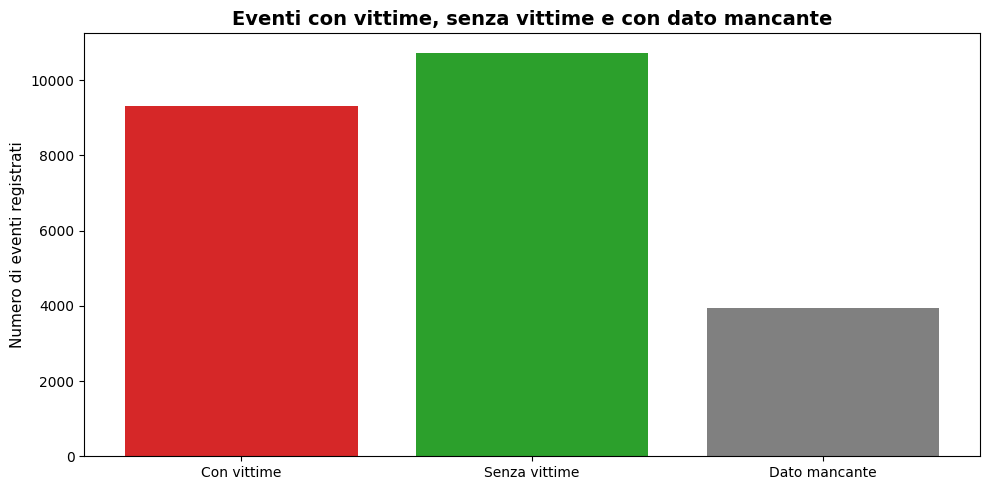

In [4]:
print(f"Eventi registrati: {len(df):,}")
print(f"Somma delle vittime nei record con dato noto: {int(df['fatalities'].sum(min_count=1)):,}")
print(f"Record con fatalities mancante: {df['fatalities'].isna().sum():,}")
print(f"Anni recuperabili: {int(df['year'].min())}–{int(df['year'].max())}")

df["classe_incidente"] = np.select(
    [df["fatalities"].isna(), df["fatalities"].gt(0)],
    ["Dato mancante", "Con vittime"], default="Senza vittime"
)
incidenti_vittime = df["classe_incidente"].value_counts().reindex(
    ["Con vittime", "Senza vittime", "Dato mancante"], fill_value=0
)
display(incidenti_vittime.rename("eventi"))
plt.bar(incidenti_vittime.index, incidenti_vittime.values, color=[COLOR_RED, COLOR_GREEN, "gray"])
plt.title("Eventi con vittime, senza vittime e con dato mancante")
plt.ylabel("Numero di eventi registrati")
plt.tight_layout()
plt.show()


# 4) In quale nazione si sono verificati più incidenti?


,country,incidenti
0,USA,4377
1,Russia,1422
2,U.K.,837
3,Canada,826
4,India,700
5,Brazil,609
6,France,550
7,Germany,516
8,China,514
9,Colombia,457


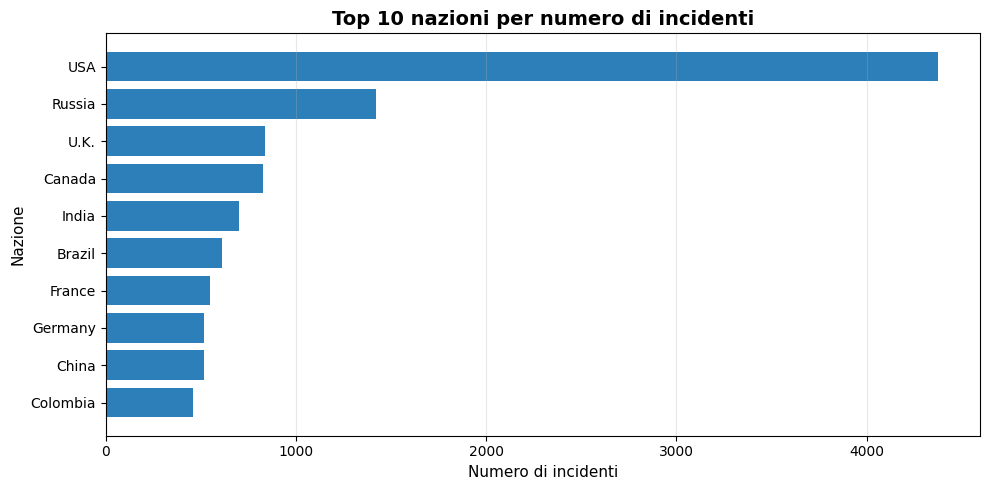

Record con Paese sconosciuto esclusi dalla classifica: 838


In [5]:
incidenti_paese = (
    df.loc[df["country"].ne("Unknown country").fillna(False), "country"]
    .dropna()
    .value_counts()
    .head(10)
)

display(incidenti_paese.rename_axis("country").reset_index(name="incidenti"))

plt.barh(
    incidenti_paese.index[::-1],
    incidenti_paese.values[::-1],
    color=COLOR_BLUE
)

plt.title("Top 10 nazioni per numero di incidenti")
plt.xlabel("Numero di incidenti")
plt.ylabel("Nazione")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("Record con Paese sconosciuto esclusi dalla classifica:", df["country"].eq("Unknown country").sum())


## Interpretazione

Le nazioni con più incidenti registrati sono quelle maggiormente rappresentate nel dataset.

Questo risultato non indica automaticamente che tali nazioni siano più pericolose: per valutare il rischio reale sarebbe necessario conoscere anche il numero totale di voli effettuati in ciascun Paese.


# 5) Gli incidenti avvengono più spesso in alcuni giorni?


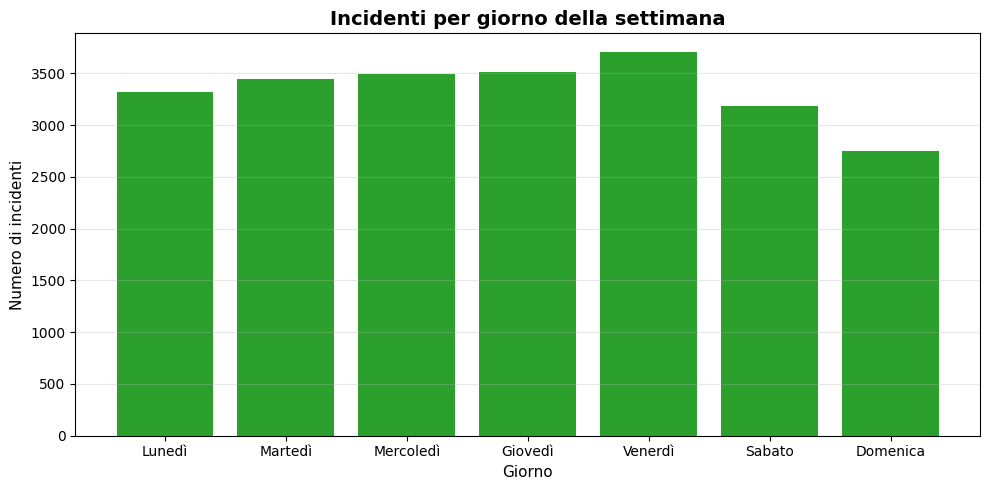

,giorno,incidenti
0,Lunedì,3317
1,Martedì,3444
2,Mercoledì,3491
3,Giovedì,3516
4,Venerdì,3701
5,Sabato,3186
6,Domenica,2753


Record inclusi: 23,408; esclusi per data incompleta/non valida: 559


In [6]:
ordine_giorni = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

etichette_giorni = [
    "Lunedì", "Martedì", "Mercoledì", "Giovedì",
    "Venerdì", "Sabato", "Domenica"
]

# Escludiamo i record senza data valida, perché in quei casi weekday è mancante
df_giorni = df.dropna(subset=["weekday"]).copy()

incidenti_giorno = (
    df_giorni["weekday"]
    .value_counts()
    .reindex(ordine_giorni, fill_value=0)
)

plt.bar(
    etichette_giorni,
    incidenti_giorno.values,
    color=COLOR_GREEN
)

plt.title("Incidenti per giorno della settimana")
plt.xlabel("Giorno")
plt.ylabel("Numero di incidenti")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(
    pd.DataFrame({
        "giorno": etichette_giorni,
        "incidenti": incidenti_giorno.values
    })
)

print(f"Record inclusi: {len(df_giorni):,}; esclusi per data incompleta/non valida: {len(df) - len(df_giorni):,}")


## Interpretazione

La distribuzione per giorno della settimana mostra quali giorni sono maggiormente rappresentati nel dataset.

I record senza una data valida vengono esclusi automaticamente, poiché per essi non è possibile calcolare il giorno della settimana.

Il risultato deve essere interpretato in modo descrittivo: senza conoscere il numero totale di voli effettuati nei diversi giorni, non è possibile stabilire se un giorno sia realmente più rischioso di un altro.


# 6) Operatori e tipologie di velivolo


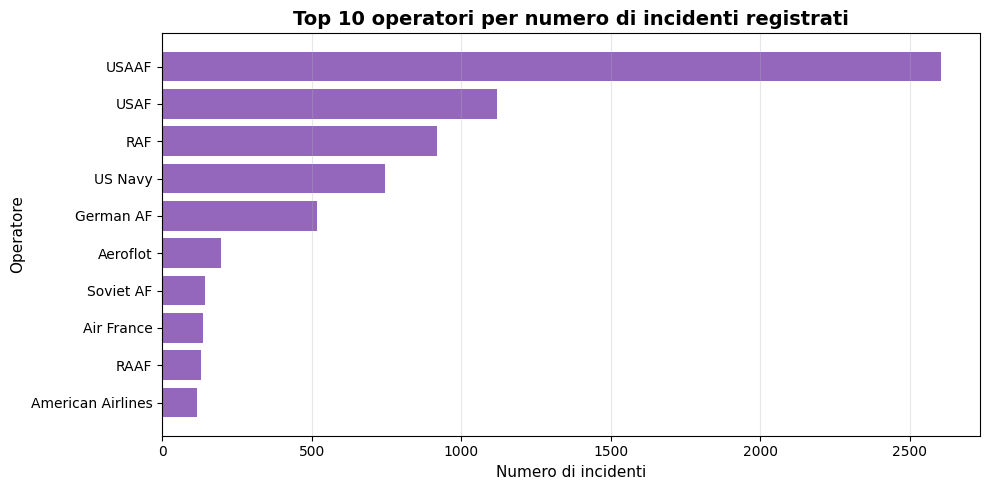

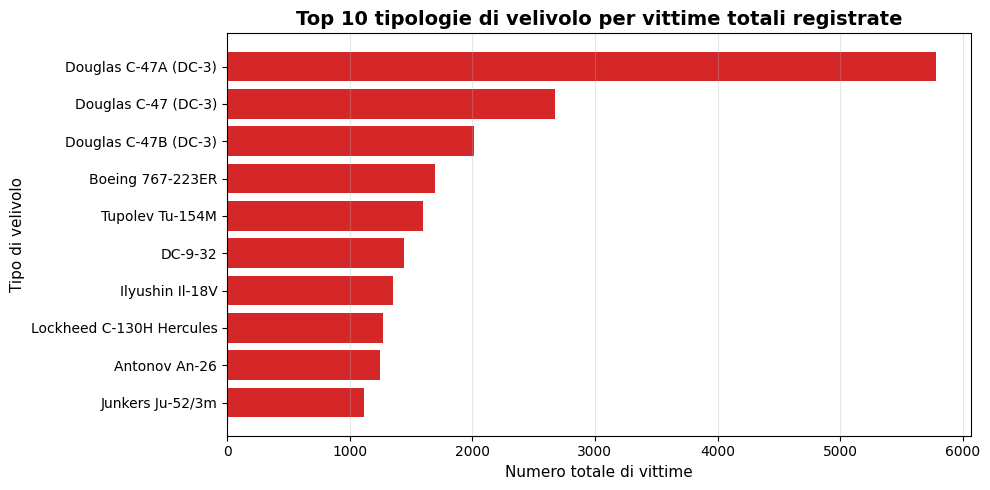

In [7]:
# Operatori con più incidenti
operatori_incidenti = (
    df.loc[~df["operator"].str.strip().str.lower().isin(["unknown", "private"]), "operator"]
    .dropna()
    .value_counts()
    .head(10)
)

plt.barh(
    operatori_incidenti.index[::-1],
    operatori_incidenti.values[::-1],
    color=COLOR_PURPLE
)

plt.title("Top 10 operatori per numero di incidenti registrati")
plt.xlabel("Numero di incidenti")
plt.ylabel("Operatore")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


# Tipologie di velivolo con più vittime
vittime_tipo = (
    df
    .dropna(subset=["type"])
    .groupby("type")["fatalities"]
    .sum(min_count=1)
    .dropna()
    .sort_values(ascending=False)
    .head(10)
)

plt.barh(
    vittime_tipo.index[::-1],
    vittime_tipo.values[::-1],
    color=COLOR_RED
)

plt.title("Top 10 tipologie di velivolo per vittime totali registrate")
plt.xlabel("Numero totale di vittime")
plt.ylabel("Tipo di velivolo")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


### Gravità degli eventi per operatore

Usiamo una soglia di **20 incidenti registrati**, non 20 voli: il dataset non contiene
il totale dei voli. La tabella mostra la media delle vittime sui soli eventi con dato noto,
il numero di casi mancanti e la copertura dell'informazione.

Per il confronto ordinato richiediamo che tutti gli eventi dell'operatore abbiano un dato
sulle vittime; in questo sottoinsieme la media coincide con il rapporto vittime/incidenti.
Questo filtro rende esplicita la completezza richiesta ma può escludere molti operatori.
Anche così, misuriamo la gravità degli eventi osservati, non la sicurezza per volo.
Le denominazioni degli operatori sono quelle della fonte, senza ricostruire fusioni o cambi di nome.
Le etichette generiche `Unknown` e `private` sono escluse dai confronti tra operatori,
perché non identificano un singolo operatore.


In [8]:
df_operatori = df.dropna(subset=["operator"]).copy()
df_operatori = df_operatori[~df_operatori["operator"].str.strip().str.lower().isin(["unknown", "private"])]
operatori = df_operatori.groupby("operator").agg(
    incidenti=("operator", "size"),
    casi_noti=("fatalities", "count"),
    vittime_totali=("fatalities", lambda s: s.sum(min_count=1)),
    vittime_medie_casi_noti=("fatalities", "mean")
)
operatori["casi_mancanti"] = operatori["incidenti"] - operatori["casi_noti"]
operatori["copertura_percento"] = 100 * operatori["casi_noti"] / operatori["incidenti"]
SOGLIA_INCIDENTI = 20
operatori_filtrati = operatori[operatori["incidenti"] >= SOGLIA_INCIDENTI].copy()
print("Operatori con almeno 20 incidenti (prime 20 righe per numerosità):")
display(operatori_filtrati.sort_values("incidenti", ascending=False).head(20).round(2))
completi = operatori_filtrati[operatori_filtrati["casi_mancanti"] == 0].copy()
print(f"Operatori sopra soglia: {len(operatori_filtrati)}; con copertura completa: {len(completi)}")
display(completi.sort_values(["vittime_medie_casi_noti", "incidenti"], ascending=[True, False]).head(15).round(2))
print("Operatori con zero vittime e nessun dato mancante, sempre sopra soglia:")
display(completi[completi["vittime_totali"] == 0].sort_values("incidenti", ascending=False))


Operatori con almeno 20 incidenti (prime 20 righe per numerosità):


,incidenti,casi_noti,vittime_totali,vittime_medie_casi_noti,casi_mancanti,copertura_percento
operator,,,,,,
USAAF,2604,851,4616.0,5.42,1753,32.68
USAF,1120,959,5905.0,6.16,161,85.62
RAF,920,716,2632.0,3.68,204,77.83
US Navy,745,500,2849.0,5.70,245,67.11
German AF,517,267,1247.0,4.67,250,51.64
Aeroflot,198,186,573.0,3.08,12,93.94
Soviet AF,142,124,1271.0,10.25,18,87.32
Air France,138,124,1676.0,13.52,14,89.86
RAAF,130,107,426.0,3.98,23,82.31


Operatori sopra soglia: 127; con copertura completa: 24


,incidenti,casi_noti,vittime_totali,vittime_medie_casi_noti,casi_mancanti,copertura_percento
operator,,,,,,
Southwest Airlines,26,26,2.0,0.08,0,100.0
British Airways,33,33,79.0,2.39,0,100.0
Delta Air Lines,81,81,309.0,3.81,0,100.0
Air Canada,29,29,139.0,4.79,0,100.0
Lufthansa,30,30,154.0,5.13,0,100.0
Eastern Air Lines,105,105,770.0,7.33,0,100.0
"Aeroflot, West Siberia",36,36,270.0,7.50,0,100.0
AVENSA,22,22,168.0,7.64,0,100.0
Indian Airlines,109,109,849.0,7.79,0,100.0


Operatori con zero vittime e nessun dato mancante, sempre sopra soglia:


,incidenti,casi_noti,vittime_totali,vittime_medie_casi_noti,casi_mancanti,copertura_percento
operator,,,,,,


## Interpretazione

Il primo grafico mostra gli operatori con il maggior numero di incidenti registrati nel dataset. Questo conteggio descrive la frequenza degli eventi associati a ciascun operatore, ma non misura la loro affidabilità o sicurezza.

Per stabilire quali operatori siano più sicuri servirebbero dati aggiuntivi, come il numero totale di voli effettuati, le ore di volo, il numero di passeggeri trasportati e il periodo di attività.

Il secondo grafico mostra le tipologie di velivolo associate al maggior numero totale di vittime. In questo caso vengono sommate le vittime degli incidenti registrati per ciascun tipo di velivolo.

Anche questo risultato non misura il rischio assoluto del modello, perché non tiene conto di quanti velivoli siano stati prodotti, di quanto siano stati utilizzati o del periodo storico in cui hanno operato.


# 7) Evoluzione temporale e 11 settembre


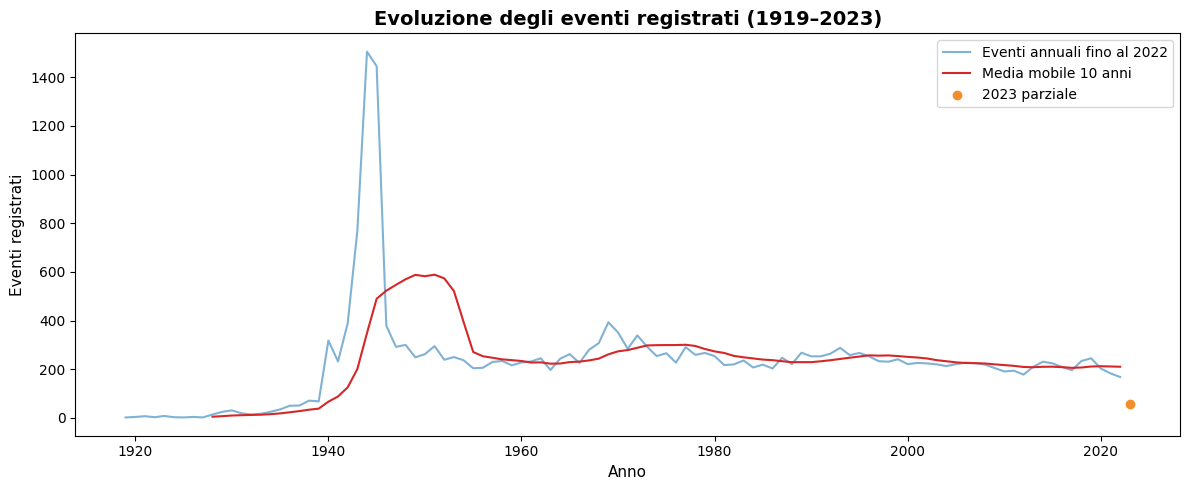

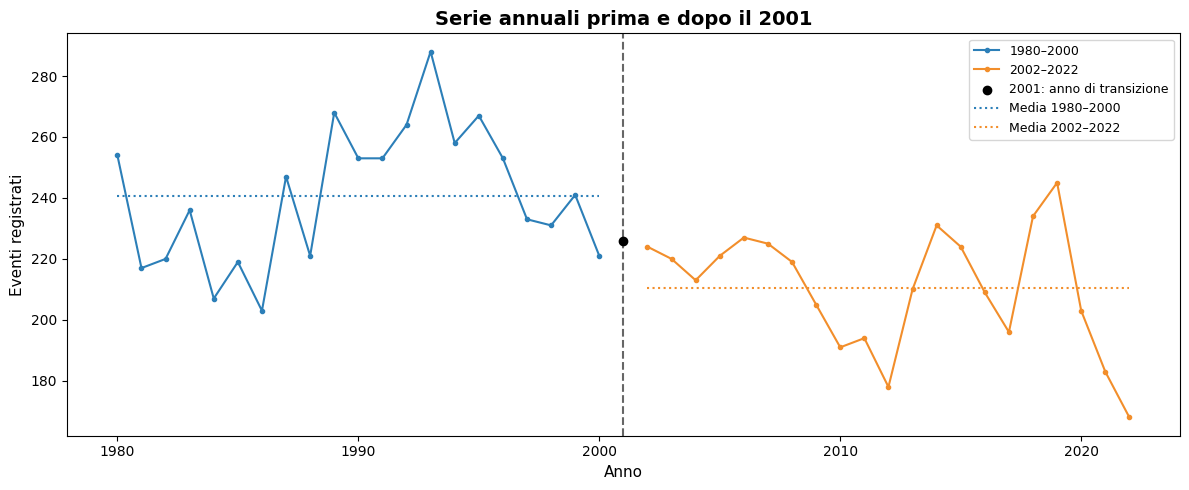

,periodo,anni,eventi_totali,eventi_medi_annui
0,1980–2000,21,5054,240.67
1,2002–2022,21,4420,210.48


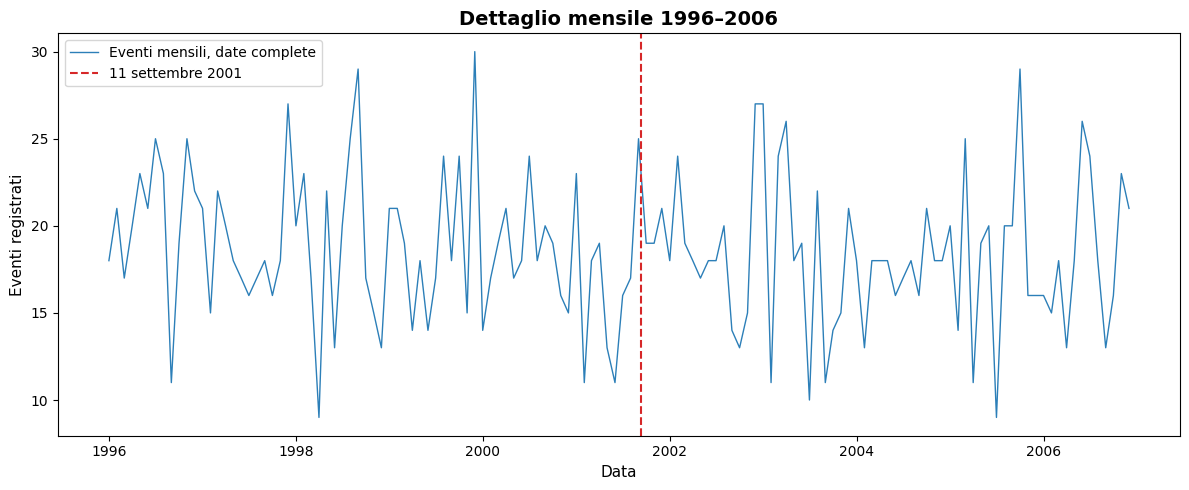

Record 1996–2006 esclusi dal dettaglio mensile per data incompleta: 64


In [9]:
incidenti_annuali = df.dropna(subset=["year"]).groupby("year").size()
incidenti_annuali.index = incidenti_annuali.index.astype(int)
incidenti_annuali = incidenti_annuali.reindex(range(1919, 2024), fill_value=0)
# Zero indica nessun evento presente nel dataset, non assenza certa di eventi reali.
# La fonte termina nel maggio 2023: quell'anno non è confrontabile con anni interi.
annuali_completi = incidenti_annuali.loc[1919:2022]
media_mobile = annuali_completi.rolling(10, min_periods=10).mean()

plt.figure(figsize=(12, 5))
plt.plot(annuali_completi.index, annuali_completi.values, color=COLOR_BLUE, alpha=.6, label="Eventi annuali fino al 2022")
plt.plot(media_mobile.index, media_mobile.values, color=COLOR_RED, label="Media mobile 10 anni")
plt.scatter([2023], [incidenti_annuali.loc[2023]], color=COLOR_ORANGE, label="2023 parziale", zorder=3)
plt.title("Evoluzione degli eventi registrati (1919–2023)")
plt.xlabel("Anno")
plt.ylabel("Eventi registrati")
plt.legend()
plt.tight_layout()
plt.show()

# Finestre di uguale durata: 21 anni prima e 21 dopo; il 2001 resta visibile.
prima = incidenti_annuali.loc[1980:2000]
dopo = incidenti_annuali.loc[2002:2022]
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(prima.index, prima.values, color=COLOR_BLUE, marker=".", label="1980–2000")
ax.plot(dopo.index, dopo.values, color=COLOR_ORANGE, marker=".", label="2002–2022")
ax.scatter([2001], [incidenti_annuali.loc[2001]], color="black", label="2001: anno di transizione")
ax.axvline(2001, color="black", linestyle="--", alpha=.6)
ax.hlines(prima.mean(), 1980, 2000, color=COLOR_BLUE, linestyle=":", label="Media 1980–2000")
ax.hlines(dopo.mean(), 2002, 2022, color=COLOR_ORANGE, linestyle=":", label="Media 2002–2022")
ax.set(title="Serie annuali prima e dopo il 2001", xlabel="Anno", ylabel="Eventi registrati")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()
display(pd.DataFrame({"periodo": ["1980–2000", "2002–2022"], "anni": [21, 21],
                      "eventi_totali": [prima.sum(), dopo.sum()],
                      "eventi_medi_annui": [prima.mean(), dopo.mean()]}).round(2))

# Dettaglio mensile attorno all'11 settembre: solo date complete.
inizio, fine = pd.Timestamp("1996-01-01"), pd.Timestamp("2006-12-31")
finestra = df.loc[df["date"].between(inizio, fine)].copy()
mensili = finestra.groupby(finestra["date"].dt.to_period("M")).size()
mensili = mensili.reindex(pd.period_range("1996-01", "2006-12", freq="M"), fill_value=0)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(mensili.index.to_timestamp(), mensili.values, color=COLOR_BLUE, linewidth=1, label="Eventi mensili, date complete")
ax.axvline(pd.Timestamp("2001-09-11"), color=COLOR_RED, linestyle="--", label="11 settembre 2001")
ax.set(title="Dettaglio mensile 1996–2006", xlabel="Data", ylabel="Eventi registrati")
ax.legend()
fig.tight_layout()
plt.show()
print("Record 1996–2006 esclusi dal dettaglio mensile per data incompleta:",
      (df["year"].between(1996, 2006) & df["date"].isna()).sum())


## Interpretazione

La media mobile descrive l'andamento di lungo periodo. Il 2023 è mostrato separatamente
perché il CSV termina il 15 maggio e non rappresenta un anno intero.
Il confronto usa due finestre di 21 anni (1980–2000 e 2002–2022); il 2001 resta visibile
nel grafico ma non entra nelle medie. Il dettaglio mensile colloca il riferimento
all'11 settembre sulla data esatta, pur aggregando gli eventi per mese.

I grafici consentono un confronto descrittivo, ma non dimostrano un effetto causale
dell'11 settembre. La fonte include operatori e categorie differenti e non contiene
il volume di voli. Le date incomplete contribuiscono al totale annuale quando l'anno
è recuperabile, ma sono escluse dal dettaglio mensile e dall'analisi dei giorni.


# 8) Bonus: cartogramma con GeoPandas


Denominazioni non abbinate, escluse dalla mappa ma mantenute nelle analisi:


,country,incidenti
2,Unknown country,838
19,P.N. Guinea,272
23,D.R. Congo,237
26,Atlantic Ocean,217
29,Pacific Ocean,175
...,...,...
225,Monaco,1
226,French Guiana,1
227,Cook Isl.,1
230,Eswatini,1


Eventi associati a denominazioni non abbinate: 2721
Eventi rappresentati sulla mappa: 21246


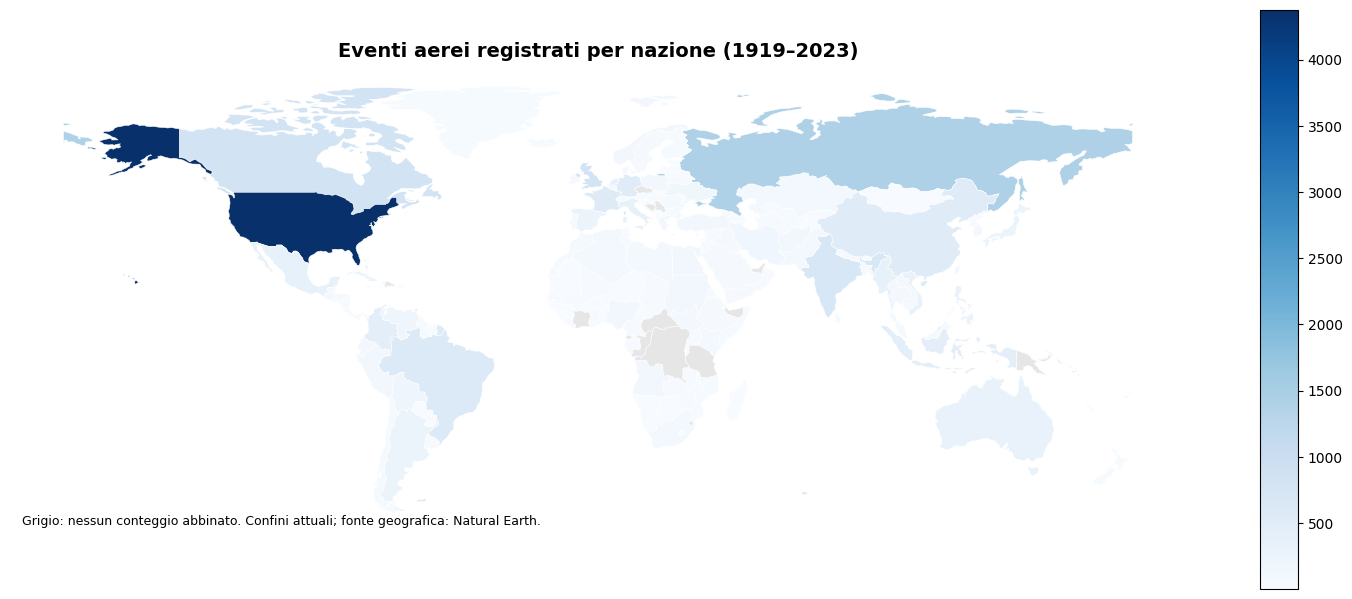

In [10]:
world_url = "https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip"
world = gpd.read_file(world_url)
world = world[world["ADMIN"] != "Antarctica"].copy()

# Solo equivalenze nominali; non attribuiamo interi Stati storici a un successore.
country_replacements = {
    "USA": "United States of America", "United States": "United States of America",
    "UK": "United Kingdom", "U.K.": "United Kingdom",
    "Czech Republic": "Czechia", "Ivory Coast": "Ivory Coast",
    "DR Congo": "Democratic Republic of the Congo",
    "Congo (Kinshasa)": "Democratic Republic of the Congo",
    "Congo (Brazzaville)": "Republic of the Congo"
}
df_mappa = df.dropna(subset=["country"]).copy()
df_mappa["country_clean"] = df_mappa["country"].str.strip().replace(country_replacements)
incidenti_mappa = df_mappa["country_clean"].value_counts().rename_axis("country").reset_index(name="incidenti")
non_abbinati = incidenti_mappa.loc[~incidenti_mappa["country"].isin(world["ADMIN"])]
print("Denominazioni non abbinate, escluse dalla mappa ma mantenute nelle analisi:")
display(non_abbinati)
print("Eventi associati a denominazioni non abbinate:", non_abbinati["incidenti"].sum())
mappa = world.merge(incidenti_mappa, left_on="ADMIN", right_on="country", how="left", validate="one_to_one")
print("Eventi rappresentati sulla mappa:", int(mappa["incidenti"].sum()))
fig, ax = plt.subplots(figsize=(15, 8))
mappa.plot(column="incidenti", cmap="Blues", linewidth=.4, edgecolor="white", legend=True,
           missing_kwds={"color": "#E6E6E6", "edgecolor": "white"}, ax=ax)
ax.set_title("Eventi aerei registrati per nazione (1919–2023)")
ax.text(.01, .02, "Grigio: nessun conteggio abbinato. Confini attuali; fonte geografica: Natural Earth.",
        transform=ax.transAxes, fontsize=9)
ax.axis("off")
plt.tight_layout()
plt.show()


## Interpretazione

La mappa rappresenta i conteggi associabili ai nomi dei Paesi nella base Natural Earth.
Le denominazioni non abbinate, incluse eventuali aree marine o nazioni storiche, sono
elencate nell'output. Non vengono attribuite arbitrariamente a uno Stato attuale.
Le zone grigie non sono una prova di assenza di incidenti.
I confini attuali e i conteggi assoluti limitano il significato della visualizzazione:
non è una mappa del rischio per volo.


# 9) Conclusioni

L'analisi degli incidenti aerei dal 1919 al 2023 ha permesso di individuare alcuni pattern descrittivi relativi alla distribuzione temporale, geografica e operativa degli eventi registrati nel dataset.

In primo luogo, gli incidenti risultano concentrati in alcune nazioni. Questo potrebbe dipendere da diversi fattori, tra cui una maggiore attività aeronautica, una maggiore estensione territoriale, una più lunga storia del trasporto aereo o una migliore disponibilità di registrazioni storiche.

L'analisi per giorno della settimana mostra differenze nella distribuzione degli incidenti, ma queste differenze non possono essere interpretate come variazioni reali del rischio senza conoscere il numero totale di voli effettuati nei diversi giorni.

Per quanto riguarda gli operatori, il dataset permette di individuare quelli con più incidenti registrati, ma non consente di stabilire quali siano i più sicuri. Per una valutazione della sicurezza servirebbero dati aggiuntivi, come numero di voli, ore di volo, passeggeri trasportati e periodo di attività.

L'analisi delle tipologie di velivolo mostra quali modelli o famiglie di velivoli sono associati al maggior numero totale di vittime registrate. Anche in questo caso, il risultato non misura il rischio assoluto del velivolo, perché non considera la diffusione del modello, gli anni di utilizzo o il numero totale di voli effettuati.

Dal punto di vista temporale, il numero di incidenti varia nel corso degli anni. La media mobile consente di osservare meglio il trend generale. Il confronto tra il periodo precedente e successivo al 2001 è stato effettuato usando la media annua degli incidenti, ma non permette di dimostrare un effetto causale diretto dell'11 settembre.

Infine, la mappa coropletica realizzata con GeoPandas consente di visualizzare la distribuzione geografica degli incidenti. La mappa è utile come rappresentazione descrittiva, ma non misura il rischio relativo delle diverse nazioni.

In [11]:
print(f"Eventi analizzati: {len(df):,}")
print(f"Vittime: {int(df['fatalities'].sum(min_count=1)):,} nei record con dato noto; {df['fatalities'].isna().sum():,} record senza informazione.")
print(f"Paese più rappresentato: {incidenti_paese.index[0]} ({incidenti_paese.iloc[0]:,} eventi).")
print(f"Tipo con maggiore somma di vittime note: {vittime_tipo.index[0]} ({int(vittime_tipo.iloc[0]):,}).")
print(f"Picco annuale fino al 2022: {annuali_completi.idxmax()} ({annuali_completi.max():,} eventi).")
print(f"Media annua 1980–2000: {prima.mean():.2f}; 2002–2022: {dopo.mean():.2f}.")


Eventi analizzati: 23,967
Vittime: 132,732 nei record con dato noto; 3,938 record senza informazione.
Paese più rappresentato: USA (4,377 eventi).
Tipo con maggiore somma di vittime note: Douglas C-47A (DC-3) (5,780).
Picco annuale fino al 2022: 1944 (1,505 eventi).
Media annua 1980–2000: 240.67; 2002–2022: 210.48.


## Limiti e sviluppi futuri

- Il dataset raccoglie eventi registrati: non include voli totali, ore di volo o
  passeggeri trasportati. Conteggi e vittime medie per evento non misurano il rischio per volo.
- Le vittime mancanti restano sconosciute. La somma disponibile non è un totale completo
  di tutte le vittime reali; la somma delle parti separate da `+` segue la notazione della fonte.
- Date incomplete, possibile copertura storica disomogenea e il 2023 parziale limitano
  i confronti temporali. Le date molto frequenti richiedono verifica sui singoli eventi.
- Le classifiche per tipo e operatore usano le denominazioni originali; non correggono
  differenze di flotta, epoca, attività militare/civile o volume operativo.
- Per un'analisi del rischio servirebbero dati di esposizione e una verifica puntuale
  della documentazione del dataset. I confronti prima/dopo restano descrittivi.

**Fonti dei file usati:** [CSV fornito per il corso](https://proai-datasets.s3.eu-west-3.amazonaws.com/aviation-accidents.csv)
e [base geografica Natural Earth](https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip).
